In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ratings = pd.read_csv("../data/ml-32m/ratings.csv")
movies  = pd.read_csv("../data/ml-32m/movies.csv")
links   = pd.read_csv("../data/ml-32m/links.csv")

print("Ratings:", ratings.shape)
print("Movies:", movies.shape)
print("Links:", links.shape)

print(ratings.head())

Ratings: (32000204, 4)
Movies: (87585, 3)
Links: (87585, 3)
   userId  movieId  rating  timestamp
0       1       17     4.0  944249077
1       1       25     1.0  944250228
2       1       29     2.0  943230976
3       1       30     5.0  944249077
4       1       32     5.0  943228858


count    200948.000000
mean        159.246193
std         282.025462
min          20.000000
25%          36.000000
50%          73.000000
75%         167.000000
max       33332.000000
dtype: float64
20+ ratings: 200,948 users
30+ ratings: 166,757 users
50+ ratings: 128,344 users
75+ ratings: 98,697 users
100+ ratings: 80,675 users
200+ ratings: 42,197 users
500+ ratings: 12,603 users


Text(0, 0.5, 'Number of Users (log scale)')

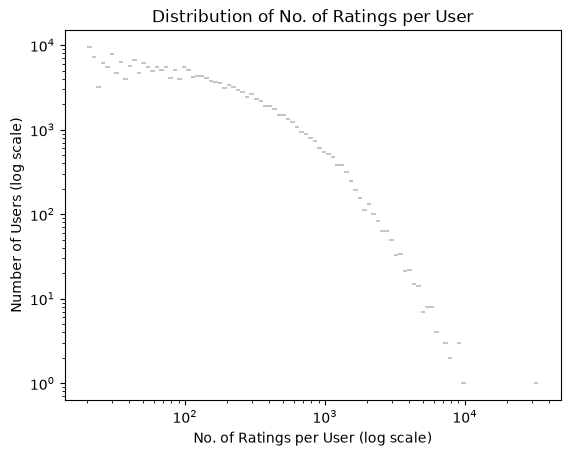

In [18]:
ratings_per_user = ratings.groupby("userId").size()

print(ratings_per_user.describe())

for threshold in [20, 30, 50, 75, 100, 200, 500]:
    n_users = (ratings_per_user >= threshold).sum()
    print(f"{threshold}+ ratings: {n_users:,} users")

sns.histplot(ratings_per_user, bins=100, log_scale=(True, True))
plt.title("Distribution of No. of Ratings per User")
plt.xlabel("No. of Ratings per User (log scale)")
plt.ylabel("Number of Users (log scale)")

Filtered User Ratings: (186467, 4)
       userId  movieId  rating   timestamp
12300      80       32     5.0  1468690943
12301      80       34     1.5  1468692491
12302      80       47     4.0  1468690774
12303      80      110     3.5  1468690883
12304      80      111     4.5  1468690917

               userId        movieId         rating     timestamp
count  186467.000000  186467.000000  186467.000000  1.864670e+05
mean    98775.557525   27497.413784       3.579379  1.261108e+09
std     57464.476139   48921.426643       1.065983  2.628191e+08
min        80.000000       1.000000       0.500000  8.292558e+08
25%     47174.000000    1201.000000       3.000000  1.000131e+09
50%     98299.000000    3089.000000       4.000000  1.240172e+09
75%    147509.000000   37763.000000       4.500000  1.501110e+09
max    200942.000000  292595.000000       5.000000  1.697076e+09

Ratings per Filtered User: count    1000.000000
mean      186.467000
std       168.742451
min        50.000000
25%     

Text(0, 0.5, 'Number of Users')

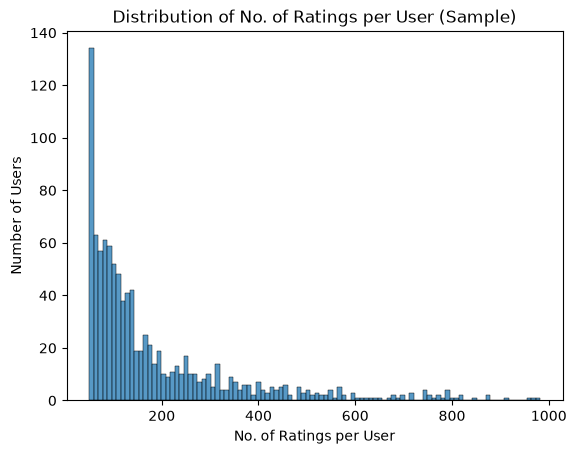

In [ ]:
#sample
filtered_users = ratings_per_user[(ratings_per_user >= 50) & (ratings_per_user <= 1000)]
filtered_users_sample = filtered_users.sample(n=1000, random_state=1)
filtered_ratings = ratings[ratings["userId"].isin(filtered_users_sample.index)]

print("Filtered User Ratings:", filtered_ratings.shape)
print(filtered_ratings.head())
print("\n", filtered_ratings.describe())

#per user data
ratings_per_filtered_user = filtered_ratings.groupby("userId").size()
print("\nRatings per Filtered User:\n", ratings_per_filtered_user.describe())

sns.histplot(ratings_per_filtered_user, bins=100, log_scale=(False, False))
plt.title("Distribution of No. of Ratings per User (Sample)")
plt.xlabel("No. of Ratings per User")
plt.ylabel("Number of Users")


Text(0, 0.5, 'Number of Users')

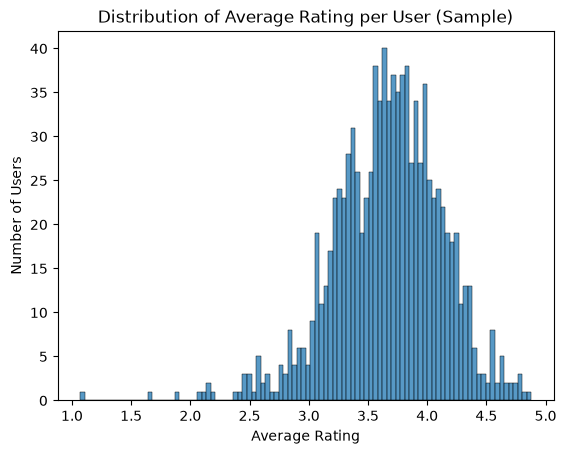

In [20]:
#plot user average rating 
#to be standardised (normalised?)
user_average_ratings = filtered_ratings.groupby("userId")["rating"].mean()

sns.histplot(user_average_ratings, bins=100, log_scale=(False, False))
plt.title("Distribution of Average Rating per User (Sample)")
plt.xlabel("Average Rating")
plt.ylabel("Number of Users")

#plot genre average?

In [21]:
#movies filter
selected_movies_id = filtered_ratings["movieId"].unique()
movies_filtered = movies[movies["movieId"].isin(selected_movies_id)]

print("Filtered Movies:", movies_filtered.shape[0])

Filtered Movies: 11301


In [22]:
genre_encoded = movies_filtered["genres"].str.get_dummies(sep="|")

movies_encoded = pd.concat(
    [movies_filtered, genre_encoded],
    axis=1,
)

movies_encoded = movies_encoded.drop(columns=["genres", "(no genres listed)"])
movies_encoded.index = movies_encoded["movieId"]
movies_encoded = movies_encoded.drop(columns=["movieId"])

print(movies_encoded.head())

                                      title  Action  Adventure  Animation  \
movieId                                                                     
1                          Toy Story (1995)       0          1          1   
2                            Jumanji (1995)       0          1          0   
3                   Grumpier Old Men (1995)       0          0          0   
4                  Waiting to Exhale (1995)       0          0          0   
5        Father of the Bride Part II (1995)       0          0          0   

         Children  Comedy  Crime  Documentary  Drama  Fantasy  Film-Noir  \
movieId                                                                    
1               1       1      0            0      0        1          0   
2               1       0      0            0      0        1          0   
3               0       1      0            0      0        0          0   
4               0       1      0            0      1        0          0   
5   

In [23]:
#clean title and extract release year

movies_encoded["Release_Year"] = (movies_encoded["title"].str.extract(r"\((\d{4})\)$")[0])
movies_encoded["Release_Year"] = pd.to_numeric(movies_encoded["Release_Year"], errors="coerce")
movies_encoded["title_clean"] = (movies_encoded["title"].str.replace(r"\s*\(\d{4}\)$", "", regex=True))
movies_encoded = movies_encoded.drop(columns=["title"])

print(movies_encoded.shape)
print(movies_encoded.head())

(11301, 21)
         Action  Adventure  Animation  Children  Comedy  Crime  Documentary  \
movieId                                                                       
1             0          1          1         1       1      0            0   
2             0          1          0         1       0      0            0   
3             0          0          0         0       1      0            0   
4             0          0          0         0       1      0            0   
5             0          0          0         0       1      0            0   

         Drama  Fantasy  Film-Noir  ...  IMAX  Musical  Mystery  Romance  \
movieId                             ...                                    
1            0        1          0  ...     0        0        0        0   
2            0        1          0  ...     0        0        0        0   
3            0        0          0  ...     0        0        0        1   
4            1        0          0  ...     0        0

In [ ]:
#add avg rating to movie feature matrix
# data leakage fix? 

avg_ratings = ratings.groupby("movieId")["rating"].mean().rename("avg_rating")
movies_encoded = movies_encoded.merge(avg_ratings, on="movieId", how="left")

print(movies_encoded.head())

         Action  Adventure  Animation  Children  Comedy  Crime  Documentary  \
movieId                                                                       
1             0          1          1         1       1      0            0   
2             0          1          0         1       0      0            0   
3             0          0          0         0       1      0            0   
4             0          0          0         0       1      0            0   
5             0          0          0         0       1      0            0   

         Drama  Fantasy  Film-Noir  ...  Musical  Mystery  Romance  Sci-Fi  \
movieId                             ...                                      
1            0        1          0  ...        0        0        0       0   
2            0        1          0  ...        0        0        0       0   
3            0        0          0  ...        0        0        1       0   
4            1        0          0  ...        0        

In [25]:
#build the feature matrix for users

users_encoded = pd.DataFrame(
    index=filtered_users_sample.index
)

users_encoded.index.name = "userId"

genre_columns = genre_encoded.columns.tolist()
genre_columns.remove("(no genres listed)")

for genre in genre_columns:
    #average of ratings for movies by genre for filtered users
    genre_movie_ids = movies_encoded.loc[movies_encoded[genre] == 1].index

    users_encoded[genre] = filtered_ratings[filtered_ratings["movieId"].isin(genre_movie_ids)].groupby("userId")["rating"].mean()

print(users_encoded.head())

          Action  Adventure  Animation  Children    Comedy     Crime  \
userId                                                                 
25348   3.708333   3.642857   3.777778  3.590909  3.611111  3.785714   
22418   3.769231   4.171053   0.500000  2.666667  3.416667  3.400000   
80048   3.200000   3.083333        NaN  3.000000  3.210526  3.444444   
52289   2.823529   2.750000   3.000000  2.833333  2.840000  2.705882   
122284  2.933333   3.615385   4.100000  3.903226  3.437500  3.291667   

        Documentary     Drama   Fantasy  Film-Noir  Horror      IMAX  \
userId                                                                 
25348           NaN  3.916667  3.807692        4.5     NaN  3.833333   
22418           NaN  3.541667  4.531250        NaN    3.75  3.854167   
80048           NaN  3.481481  3.333333        NaN     NaN  4.000000   
52289           NaN  3.118644  3.000000        NaN    2.80  3.000000   
122284          NaN  3.693548  3.619048        4.0    2.68  4.6

In [26]:
#build combined table 
user_features = users_encoded.add_prefix("user_")
movie_features = movies_encoded.add_prefix("movie_")
training_data = filtered_ratings.merge(user_features, on="userId", how="left")
training_data = training_data.merge(movie_features, on="movieId", how="left")

print("Training Data:", training_data.shape)
print(training_data.head())

Training Data: (186467, 45)
   userId  movieId  rating   timestamp  user_Action  user_Adventure  \
0      80       32     5.0  1468690943       3.6775        3.659664   
1      80       34     1.5  1468692491       3.6775        3.659664   
2      80       47     4.0  1468690774       3.6775        3.659664   
3      80      110     3.5  1468690883       3.6775        3.659664   
4      80      111     4.5  1468690917       3.6775        3.659664   

   user_Animation  user_Children  user_Comedy  user_Crime  ...  movie_Musical  \
0            3.75            2.6     3.291667       3.875  ...              0   
1            3.75            2.6     3.291667       3.875  ...              0   
2            3.75            2.6     3.291667       3.875  ...              0   
3            3.75            2.6     3.291667       3.875  ...              0   
4            3.75            2.6     3.291667       3.875  ...              0   

   movie_Mystery  movie_Romance  movie_Sci-Fi  movie_Thril

In [34]:
#set X and Y
user_cols = ["user_" + col for col in users_encoded.columns]
movie_cols = ["movie_" + col 
              for col in movies_encoded.columns
              if col not in ["title_clean", "Release_Year"]
              ]

X_user = training_data[user_cols]
X_movie = training_data[movie_cols]
y = training_data["rating"]

print("X_user shape:", X_user.shape)
print("X_movie shape:", X_movie.shape)
print("y shape:", y.shape)

X_user shape: (186467, 19)
X_movie shape: (186467, 20)
y shape: (186467,)


In [35]:
#export the feature matrices to CSV files
X_user.to_csv(
    "../data/X_user.csv",
    index=False
)

X_movie.to_csv(
    "../data/X_movie.csv",
    index=False
)

y.to_csv(
    "../data/y.csv",
    index=False
)

In [29]:
#recency weighting rating*beta/beta, beta > 1 for ratings in the most recent year